# Reconstruct: 1 イベント 1 行の再構成ツリー

それまでのモジュールの結果をまとめ、**全イベントで 1 行**のツリー `Reconstruct/single_hit` を作ります。
SMILE_tool_box の `Reconstruct`(ツリー `s2t`)と同じ並び・同じ更新規則です。

### `err_flag` と値の更新規則

| 条件 | `err_flag` | 書かれる値 |
|---|---|---|
| Ee・Eg が有効、電子方向 Ve_TRA あり | 0 | すべて新しい値。運動学の角度も計算 |
| Ee・Eg が有効、Ve_TRA なし | 前の行のまま | `Ke`, `Eg`, `Pg` などは新しい値、角度は前の行のまま、`Ve_TRA_fit_status` は 1 |
| それ以外 | 1 | 角度・`Ve_TRA`・`Track_Min/Max` はセンチネル(`0xffffffff`)、`Eg`, `Ke`, `Pg` は**前の行のまま** |

参照と行単位で一致させるため、この(少し癖のある)規則をそのまま再現しています。
**解析には `err_flag == 0` の行だけを使ってください。**

### 運動学

`Eg`, `Ke` から、散乱角 `phi_kin`、反跳角 `psi_kin`、散乱ガンマ線と反跳電子のなす角 `alpha_kin` [deg] を求めます
(`m_e c^2 = 510.9989461 keV`)。

$$\cos\phi = 1 - \frac{m_e c^2}{E_g + K_e}\frac{K_e}{E_g},\quad
\cos\psi = \left(1 + \frac{m_e c^2}{E_g + K_e}\right)\sqrt{\frac{K_e}{K_e + 2 m_e c^2}},\quad
\cos\alpha = \left(1 - \frac{m_e c^2}{E_g}\right)\sqrt{\frac{K_e}{K_e + 2 m_e c^2}}$$

In [1]:
import sys
from pathlib import Path
here = Path.cwd().resolve()
sys.path.insert(0, str(next(p for p in [here, *here.parents] if (p / "tutorial_utils.py").exists())))
import tutorial_utils as tu

import numpy as np
import matplotlib.pyplot as plt
ROOT = tu.setup_pyroot()

## 1. データのダウンロード

このチュートリアルでは 20190701 の較正データ **Per02**(線源を TPC の上方 z = −1626 mm に置いた測定)を使います。
生データ(約 17 GB)とパラメータはリポジトリに含まれていないので、研究室サーバーから手元にコピーします。

```bash
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/
```

(`<user>` は自分のアカウント名)

- 途中で切れても同じコマンドで続きからコピーされます。
- `~/smile2p_data` 以外に置いた場合は、環境変数 `SMILE2P_DATA` にその場所を設定してください。
- サーバー上で実行する場合はコピーしなくても動きます(サーバー上の場所をそのまま使います)。
  ただし実行時間の大半は生データの読み込みなので、**手元のディスクにコピーした方が大幅に速く**なります
  (ネットワーク越しの場所から読むと約 10 倍遅い)。

In [2]:
tu.print_download_instructions("Per02")
DATA_TOP = tu.check_data("Per02")

# 生データ(Per02)とパラメータを ~/smile2p_data にコピーする
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/


data OK: /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata  (Per02: 554 raw files)


## 2. 再構成ツリーを読む

In [3]:
# 全チェーンの出力(DataIO と共有、Per02 の先頭 50000 イベント)
OUT = tu.get_reconstructed("Per02", 50000)

Per02_50000.root は既にあるので再実行しません(overwrite=True で作り直し)


## 3. `err_flag` の内訳

In [4]:
allrows = tu.load_single_hit(OUT, branches=["err_flag"], valid_only=False)["err_flag"]
vals, counts = np.unique(allrows, return_counts=True)
for v, c in zip(vals, counts):
    print(f"err_flag = {v}: {c:6d} ({c / len(allrows):.1%})")

err_flag = 0:  26697 (53.4%)
err_flag = 1:  23303 (46.6%)


## 4. エネルギーと運動学

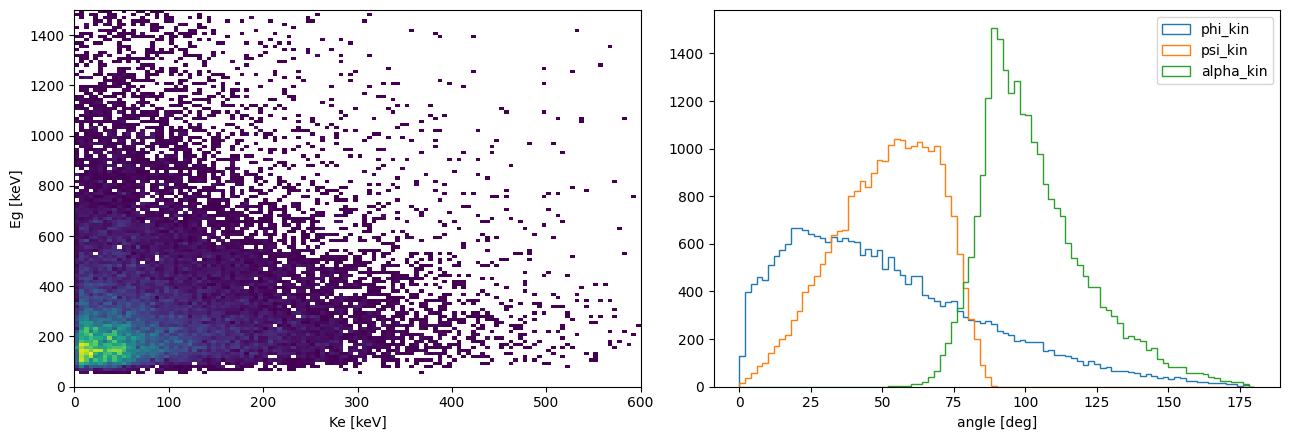

In [5]:
ev = tu.load_single_hit(OUT)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist2d(ev["Ke"], ev["Eg"], bins=[120, 120], range=[[0, 600], [0, 1500]], cmin=1)
ax[0].set_xlabel("Ke [keV]"); ax[0].set_ylabel("Eg [keV]")
for name in ["phi_kin", "psi_kin", "alpha_kin"]:
    x = ev[name]; ax[1].hist(x[(x >= 0) & (x <= 180)], bins=90, range=(0, 180), histtype="step", label=name)
ax[1].set_xlabel("angle [deg]"); ax[1].legend()
fig.tight_layout(); plt.show()